# 07. Đánh giá tổng hợp và thí nghiệm

## Import và đọc tham số đã chọn

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.tools import load_features, train_test, scores, summarize, linear_w, flip_near_boundary, add_outliers
from src.models import SVM, LSSVM, PinSVM, WaveSVM

data = load_features()
MODELS = {"SVM": SVM, "LS-SVM": LSSVM, "Pin-SVM": PinSVM, "Wave-SVM": WaveSVM}
NAMES = list(MODELS)
tuning = {name: json.load(open(f"../reports/tables/tuning_{name}.json")) for name in NAMES}
pd.DataFrame({name: tuning[name]["best"] for name in NAMES}).T

,kernel,C,gamma,tau,a,lam,k
SVM,rbf,1,0.01,NaN,NaN,NaN,NaN
LS-SVM,rbf,0.1,0.01,NaN,NaN,NaN,NaN
Pin-SVM,rbf,1,0.01,1.0,NaN,NaN,NaN
Wave-SVM,rbf,0.1,0.2,NaN,0.5,1.0,32


## Bảng kết quả

In [2]:
X_train, y_train, X_test, y_test, train, test = train_test(data)
majority = {"model": "Majority (luôn Tăng)", "seed": 0, **scores(y_test, np.ones(len(y_test), dtype=int))}
for year in sorted(set(test.index.year)):
    majority[f"BalAcc_{year}"] = 0.5
allres = pd.concat([pd.DataFrame([majority])] +
                   [pd.read_csv(f"../reports/tables/test_{name}.csv") for name in NAMES], ignore_index=True)
cols = ["Accuracy", "BalAcc", "F1", "AUC", "MCC", "UpRate", "time_s", "nonzero"]
main = summarize(allres, cols)
main.to_csv("../reports/tables/table_main.csv")
main

,Accuracy,BalAcc,F1,AUC,MCC,UpRate,time_s,nonzero
model,,,,,,,,
Majority (luôn Tăng),0.5783,0.5000,0.7328,nan,0.0000,1.0000,nan,nan
SVM,0.5261,0.5133,0.5922,0.5070,0.0267,0.5837,0.0913,0.9619
LS-SVM,0.5141,0.5021,0.5794,0.5119,0.0041,0.5770,0.2006,1.0000
Pin-SVM,0.5234,0.5080,0.5955,0.5061,0.0161,0.5997,4.0784,1.0000
Wave-SVM,0.4925 ± 0.0709,0.5009 ± 0.0086,0.3784 ± 0.3153,0.4971 ± 0.0229,0.0021 ± 0.0450,0.4465 ± 0.4617,1.5861 ± 0.1855,1.0000


## Độ ổn định theo năm 

In [3]:
year_cols = [c for c in allres.columns if c.startswith("BalAcc_20")]
by_year = allres.groupby("model", sort=False)[year_cols].mean()
by_year["std giữa các năm"] = by_year.std(axis=1)
by_year.round(4).to_csv("../reports/tables/table_by_year.csv")
by_year.round(4)

,BalAcc_2023,BalAcc_2024,BalAcc_2025,std giữa các năm
model,,,,
Majority (luôn Tăng),0.5000,0.5000,0.5000,0.0000
SVM,0.5327,0.4912,0.5134,0.0208
LS-SVM,0.5106,0.4851,0.5069,0.0138
Pin-SVM,0.5453,0.4809,0.4952,0.0338
Wave-SVM,0.5011,0.5019,0.4994,0.0012


## Chọn tham số tuyến tính cho các thí nghiệm nhiễu

In [4]:
def best_linear(rows, **fixed):
    candidates = [r for r in rows if r["params"]["kernel"] == "linear"
                  and all(r["params"].get(key) == value for key, value in fixed.items())]
    return max(candidates, key=lambda r: r["BalAcc"])["params"]

robust = {name: best_linear(tuning[name]["rows"]) for name in ["SVM", "LS-SVM", "Pin-SVM"]}
robust["Wave-SVM"] = best_linear(tuning["Wave-SVM"]["rows"], k=256)
pd.DataFrame(robust).T

,kernel,C,tau,a,lam,k
SVM,linear,0.01,NaN,NaN,NaN,NaN
LS-SVM,linear,0.01,NaN,NaN,NaN,NaN
Pin-SVM,linear,0.01,0.5,NaN,NaN,NaN
Wave-SVM,linear,0.01,NaN,2.0,0.5,256


## Hàm chạy một thí nghiệm nhiễu

In [5]:
# hướng "Tăng" chung cho mọi mô hình: pháp tuyến của một SVM tuyến tính trên dữ liệu sạch
ref_direction, _ = linear_w(SVM(C=1.0).fit(X_train, y_train), X_train.shape[1])


def noise_experiment(name, kind, rates, seeds=range(5)):
    ModelClass, params = MODELS[name], robust[name]
    rows = []
    for s in seeds:
        clean = ModelClass(**params, seed=s).fit(X_train, y_train)           # mô hình trên dữ liệu sạch
        clean_pred = clean.predict(X_test)
        w_clean, _ = linear_w(clean, X_train.shape[1])
        for rate in rates:
            if kind == "label":
                X_noisy = X_train
                y_noisy = flip_near_boundary(y_train, train["r_next"].to_numpy(), rate)
            else:
                X_noisy, y_noisy = add_outliers(X_train, y_train, rate, ref_direction,
                                                rng=np.random.default_rng(100 + s))
            noisy = ModelClass(**params, seed=s).fit(X_noisy, y_noisy)
            decision = noisy.decision_function(X_test)
            pred = np.where(decision >= 0, 1, -1)
            w_noisy, _ = linear_w(noisy, X_train.shape[1])
            cos_w = w_noisy @ w_clean / (np.linalg.norm(w_noisy) * np.linalg.norm(w_clean) + 1e-12)
            rows.append({"model": name, "seed": s, "rate": rate, **scores(y_test, pred, decision),
                         "agree": np.mean(pred == clean_pred), "cos_w": cos_w})
    return pd.DataFrame(rows)

## Thí nghiệm 1: đảo nhãn quanh biên

In [6]:
e1 = pd.concat([noise_experiment(name, "label", [0.0, 0.05, 0.10, 0.20]) for name in NAMES])
e1.to_csv("../reports/tables/exp1_label_noise.csv", index=False)
e1.groupby(["model", "rate"], sort=False)[["BalAcc", "agree", "cos_w"]].agg(["mean", "std"]).round(4)

BalAcc           agree           cos_w        
                 mean     std    mean     std    mean     std
model    rate                                                
SVM      0.00  0.5127  0.0000  1.0000  0.0000  1.0000  0.0000
         0.05  0.5006  0.0000  0.9290  0.0000  0.9183  0.0000
         0.10  0.4980  0.0000  0.8675  0.0000  0.8403  0.0000
         0.20  0.5021  0.0000  0.7952  0.0000  0.8086  0.0000
LS-SVM   0.00  0.5091  0.0000  1.0000  0.0000  1.0000  0.0000
         0.05  0.5008  0.0000  0.8942  0.0000  0.7841  0.0000
         0.10  0.5004  0.0000  0.8340  0.0000  0.7170  0.0000
         0.20  0.5212  0.0000  0.8019  0.0000  0.6262  0.0000
Pin-SVM  0.00  0.5072  0.0000  1.0000  0.0000  1.0000  0.0000
         0.05  0.5019  0.0000  0.9237  0.0000  0.9056  0.0000
         0.10  0.4968  0.0000  0.8594  0.0000  0.8464  0.0000
         0.20  0.4963  0.0000  0.7965  0.0000  0.8206  0.0000
Wave-SVM 0.00  0.5104  0.0045  1.0000  0.0000  1.0000  0.0000
         0.05  0.5101  0.0073  0.8996  0.1362  0.8476  0.3018
         0.10  0.5116  0.0046  0.9312  0.0511  0.9415  0.0731
         0.20  0.5000  0.0000  0.6552  0.0141  0.2297  0.2053

## Thí nghiệm 2: outlier sai nhãn (Bảng 5.6) và Hình 5.2

BalAcc           agree           cos_w        
                 mean     std    mean     std    mean     std
model    rate                                                
SVM      0.00  0.5127  0.0000  1.0000  0.0000  1.0000  0.0000
         0.01  0.5110  0.0048  0.8846  0.0031  0.5415  0.0084
         0.03  0.5032  0.0039  0.5797  0.0028  0.3296  0.0061
         0.05  0.5000  0.0000  0.5194  0.0000  0.0034  0.0079
LS-SVM   0.00  0.5091  0.0000  1.0000  0.0000  1.0000  0.0000
         0.01  0.5010  0.0010  0.9197  0.0009  0.2589  0.0041
         0.03  0.5049  0.0011  0.8324  0.0048  0.2364  0.0027
         0.05  0.4904  0.0016  0.7435  0.0028  0.2250  0.0030
Pin-SVM  0.00  0.5072  0.0000  1.0000  0.0000  1.0000  0.0000
         0.01  0.5026  0.0026  0.8565  0.0183  0.5514  0.0119
         0.03  0.4989  0.0010  0.5266  0.0049  0.1793  0.0341
         0.05  0.5000  0.0000  0.5194  0.0000 -0.0262  0.0033
Wave-SVM 0.00  0.5104  0.0045  1.0000  0.0000  1.0000  0.0000
         0.01  0.5000  0.0000  0.5912  0.1411  0.0760  0.2269
         0.03  0.5000  0.0000  0.6552  0.0141 -0.0219  0.0221
         0.05  0.5000  0.0000  0.6552  0.0141  0.0280  0.0364

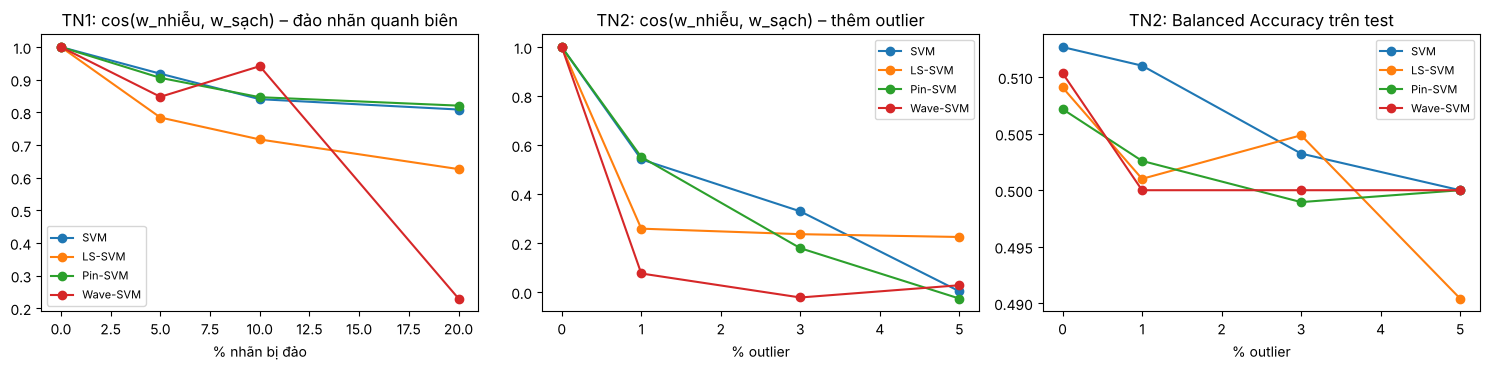

In [7]:
e2 = pd.concat([noise_experiment(name, "outlier", [0.0, 0.01, 0.03, 0.05]) for name in NAMES])
e2.to_csv("../reports/tables/exp2_outliers.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name in NAMES:
    g1 = e1[e1.model == name].groupby("rate")["cos_w"].mean()
    g2 = e2[e2.model == name].groupby("rate")["cos_w"].mean()
    g3 = e2[e2.model == name].groupby("rate")["BalAcc"].mean()
    ax[0].plot(g1.index * 100, g1.values, "o-", label=name)
    ax[1].plot(g2.index * 100, g2.values, "o-", label=name)
    ax[2].plot(g3.index * 100, g3.values, "o-", label=name)
ax[0].set_title("TN1: cos(w_nhiễu, w_sạch) – đảo nhãn quanh biên"); ax[0].set_xlabel("% nhãn bị đảo")
ax[1].set_title("TN2: cos(w_nhiễu, w_sạch) – thêm outlier"); ax[1].set_xlabel("% outlier")
ax[2].set_title("TN2: Balanced Accuracy trên test"); ax[2].set_xlabel("% outlier")
for a_ in ax:
    a_.legend(fontsize=8)
plt.tight_layout()
fig.savefig("../reports/figures/fig_noise_experiments.png", dpi=150, bbox_inches="tight")
e2.groupby(["model", "rate"], sort=False)[["BalAcc", "agree", "cos_w"]].agg(["mean", "std"]).round(4)

## Đối chứng bán tổng hợp (Bảng 5.7, Hình 5.3)

mean                             std                        
rate        0.00    0.01    0.05    0.10    0.00    0.01    0.05    0.10
model                                                                   
SVM       0.7510  0.7376  0.7376  0.7197  0.0000  0.0034  0.0038  0.0012
LS-SVM    0.7497  0.7357  0.7290  0.7272  0.0000  0.0007  0.0034  0.0022
Pin-SVM   0.7416  0.7403  0.7341  0.7237  0.0000  0.0027  0.0015  0.0047
Wave-SVM  0.7566  0.7505  0.7454  0.7290  0.0035  0.0026  0.0056  0.0101

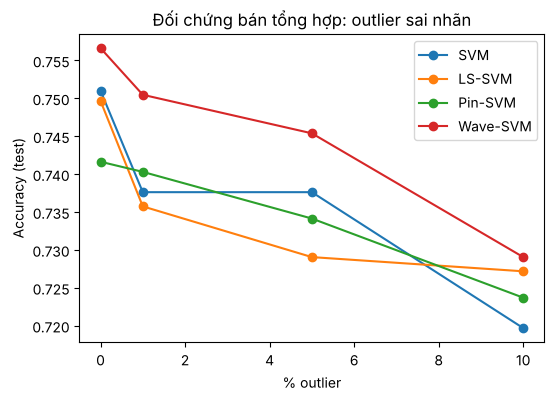

In [8]:
rng = np.random.default_rng(42)
beta = rng.normal(size=X_train.shape[1])
beta /= np.linalg.norm(beta)
y_train_syn = np.where(X_train @ beta + 0.6 * np.random.default_rng(1).normal(size=len(X_train)) > 0, 1, -1)
y_test_syn = np.where(X_test @ beta + 0.6 * np.random.default_rng(2).normal(size=len(X_test)) > 0, 1, -1)
direction_syn, _ = linear_w(SVM(C=1.0).fit(X_train, y_train_syn), X_train.shape[1])

syn_params = {"SVM": {"C": 1}, "LS-SVM": {"C": 1}, "Pin-SVM": {"C": 1, "tau": 0.5},
              "Wave-SVM": {"C": 1, "a": 2.0, "lam": 0.5, "k": 256}}
rows = []
for name in NAMES:
    for s in range(5):
        for rate in [0.0, 0.01, 0.05, 0.10]:
            X_noisy, y_noisy = add_outliers(X_train, y_train_syn, rate, direction_syn,
                                            rng=np.random.default_rng(100 + s))
            m = MODELS[name](**syn_params[name], seed=s).fit(X_noisy, y_noisy)
            rows.append({"model": name, "seed": s, "rate": rate,
                         **scores(y_test_syn, m.predict(X_test), m.decision_function(X_test))})
e2b = pd.DataFrame(rows)
e2b.to_csv("../reports/tables/exp2b_semisynthetic.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
for name in NAMES:
    g = e2b[e2b.model == name].groupby("rate")["Accuracy"].mean()
    ax.plot(g.index * 100, g.values, "o-", label=name)
ax.set_xlabel("% outlier"); ax.set_ylabel("Accuracy (test)"); ax.legend()
ax.set_title("Đối chứng bán tổng hợp: outlier sai nhãn")
fig.savefig("../reports/figures/fig_semisynthetic.png", dpi=150, bbox_inches="tight")
e2b.groupby(["model", "rate"], sort=False)["Accuracy"].agg(["mean", "std"]).unstack("rate").round(4)

## Thí nghiệm 3: thời gian huấn luyện theo số mẫu (Bảng 5.8, Hình 5.4)

model,LS-SVM,Pin-SVM,SVM,Wave-SVM
n,,,,
250,0.0013,0.0244,0.0026,0.0473
500,0.0068,0.1243,0.0069,0.0792
1000,0.0395,0.9205,0.0244,0.0800
1500,0.1045,2.6381,0.0531,0.0798
1700,0.1329,3.3278,0.0655,0.0809


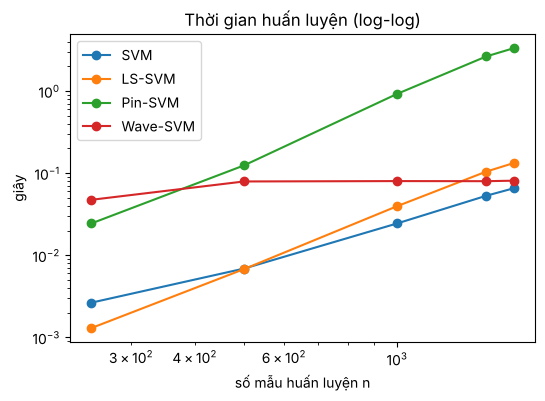

In [9]:
rows = []
for name in NAMES:
    for n in [250, 500, 1000, 1500, 1700]:
        X_n, y_n = X_train[-n:], y_train[-n:]          # n phiên gần nhất
        times = [MODELS[name](**robust[name], seed=r).fit(X_n, y_n).train_time_ for r in range(3)]
        rows.append({"model": name, "n": n, "time_s": float(np.median(times))})
e3 = pd.DataFrame(rows)
e3.to_csv("../reports/tables/exp3_timing.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
for name in NAMES:
    g = e3[e3.model == name]
    ax.loglog(g.n, g.time_s, "o-", label=name)
ax.set_xlabel("số mẫu huấn luyện n"); ax.set_ylabel("giây"); ax.legend(); ax.set_title("Thời gian huấn luyện (log-log)")
fig.savefig("../reports/figures/fig_timing.png", dpi=150, bbox_inches="tight")
e3.pivot(index="n", columns="model", values="time_s").round(4)

## Độ nhạy tham số (Bảng 5.9)

In [10]:
rows = []
for name in NAMES:
    values = np.array([r["BalAcc"] for r in tuning[name]["rows"]])
    rows.append({"model": name, "n_configs": len(values), "best": values.max(), "worst": values.min(),
                 "range": values.max() - values.min(), "std_over_grid": values.std()})
sensitivity = pd.DataFrame(rows).set_index("model")
sensitivity.round(4).to_csv("../reports/tables/table_sensitivity.csv")
sensitivity.round(4)

,n_configs,best,worst,range,std_over_grid
model,,,,,
SVM,13,0.5182,0.4656,0.0526,0.0159
LS-SVM,13,0.5110,0.4781,0.0329,0.0114
Pin-SVM,39,0.5234,0.4653,0.0581,0.0147
Wave-SVM,132,0.5282,0.4830,0.0452,0.0089
